# ViTMRI prediction comparison — fold 4
Read `result/split_ViT_gbm.csv_4_predictions.csv` without loading MRI images or a model checkpoint.

These are **survival-class predictions**, not tumor segmentation masks. Classes 0–3 run from shortest to longest survival. Each CSV row is a saved sample prediction; repeated patient IDs are combined by averaging class probabilities for the patient-level plots below.


In [106]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "result").is_dir():
    ROOT = ROOT.parent
PREDICTION_PATH = ROOT / "result/split_ViT_lgg_2_predictions.csv"
results = pd.read_csv(PREDICTION_PATH)
OUTPUT_DIR = ROOT / "result/comparisons/mri_visualization"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_PREFIX = PREDICTION_PATH.stem.replace("_predictions", "")

def save_plot(filename):
    path = OUTPUT_DIR / filename
    plt.gcf().savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
    print("Saved:", path)
print(f"{len(results)} sample predictions; {results['case_id'].nunique()} patients")
print(f"Sample accuracy: {(results['label'] == results['prediction']).mean():.1%}")
display(results.head())


64 sample predictions; 16 patients
Sample accuracy: 17.2%


,case_id,label,prediction,correct,event_time,censorship,risk,inference_time_seconds,prob_class_0,prob_class_1,prob_class_2,prob_class_3
0,TCGA-CS-5393,2,1,False,40.733334,1.0,-1.447241,0.002663,0.222919,0.296385,0.291232,0.189464
1,TCGA-CS-5393,2,1,False,40.733334,1.0,-1.509956,0.002663,0.228173,0.272029,0.261468,0.238331
2,TCGA-CS-5393,2,3,False,40.733334,1.0,-1.538895,0.002663,0.254489,0.233559,0.230521,0.281431
3,TCGA-CS-5393,2,2,True,40.733334,1.0,-1.422734,0.002663,0.256130,0.261206,0.286463,0.196201
4,TCGA-CS-6188,2,2,True,27.133333,0.0,-1.588665,0.002663,0.208518,0.255507,0.274767,0.261207


In [107]:
# Average probabilities across samples belonging to the same patient.
prob_cols = [f"prob_class_{i}" for i in range(4)]
if (results.groupby("case_id")["label"].nunique() > 1).any():
    raise ValueError("A patient has inconsistent reference labels.")
patients = results.groupby("case_id")[prob_cols].mean()
patients["label"] = results.groupby("case_id")["label"].first().astype(int)
patients["prediction"] = patients[prob_cols].to_numpy().argmax(axis=1)
patients["correct"] = patients["label"] == patients["prediction"]
print(f"Patient accuracy (averaged probabilities): {patients['correct'].mean():.1%}")
display(patients[["label", "prediction", "correct"]])


Patient accuracy (averaged probabilities): 12.5%


,label,prediction,correct
case_id,,,
TCGA-CS-5393,2,2,True
TCGA-CS-6188,2,3,False
TCGA-CS-6669,3,2,False
TCGA-DU-5872,1,3,False
TCGA-DU-7008,3,1,False
TCGA-DU-7018,2,3,False
TCGA-DU-7299,3,2,False
TCGA-DU-7304,1,3,False
TCGA-DU-8164,1,0,False


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/split_ViT_lgg_2_class_comparison.png


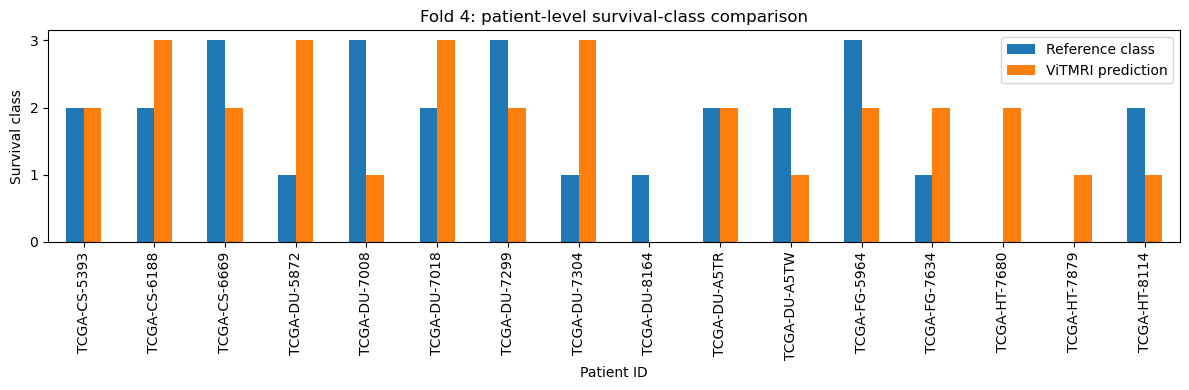

In [108]:
# Compare reference and predicted survival classes for every patient.
patients[["label", "prediction"]].rename(
    columns={"label": "Reference class", "prediction": "ViTMRI prediction"}
).plot.bar(figsize=(12, 4), rot=90)
plt.title("Fold 4: patient-level survival-class comparison")
plt.xlabel("Patient ID")
plt.ylabel("Survival class")
plt.yticks(range(4))
plt.tight_layout()
save_plot(f"{PLOT_PREFIX}_class_comparison.png")
plt.show()


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/split_ViT_lgg_2_predictions_confusion_matrix.png


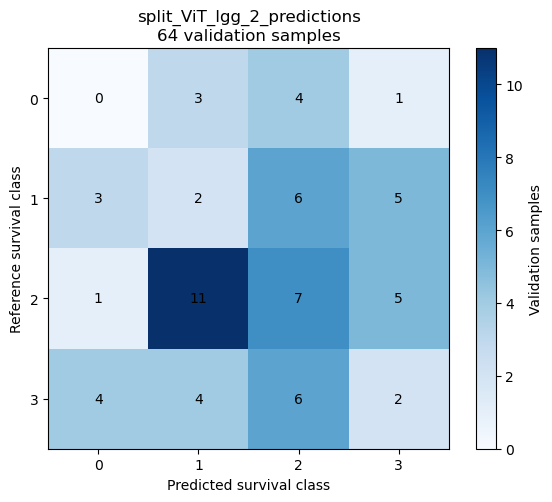

Included all 64 validation samples from this fold.


In [109]:
# Show all validation samples from the single fold selected by PREDICTION_PATH.
validation = pd.read_csv(PREDICTION_PATH)
confusion = pd.crosstab(validation["label"], validation["prediction"]).reindex(
    index=range(4), columns=range(4), fill_value=0
).to_numpy()
assert confusion.sum() == len(validation), "Unexpected class labels in the CSV."

fig, ax = plt.subplots(figsize=(6, 5))
heat = ax.imshow(confusion, cmap="Blues")
for row in range(4):
    for column in range(4):
        ax.text(column, row, confusion[row, column], ha="center", va="center")
ax.set(xticks=range(4), yticks=range(4), xlabel="Predicted survival class",
       ylabel="Reference survival class",
       title=f"{PREDICTION_PATH.stem}\n{len(validation)} validation samples")
fig.colorbar(heat, ax=ax, label="Validation samples")
fig.tight_layout()
save_plot(f"{PREDICTION_PATH.stem}_confusion_matrix.png")
plt.show()
print(f"Included all {len(validation)} validation samples from this fold.")


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/split_ViT_lgg_2_TCGA-CS-5393_probabilities.png


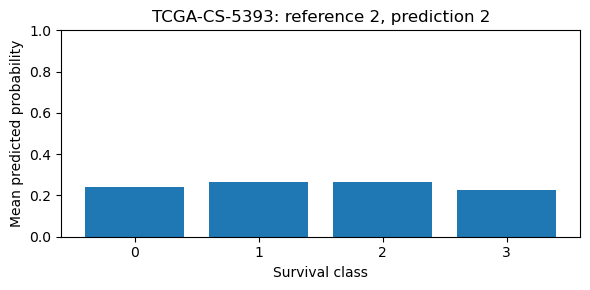

In [110]:
# Choose a patient to inspect the averaged class probabilities.
PATIENT_ID = patients.index[0]  # Replace with another ID from the table above.
patient = patients.loc[PATIENT_ID]
plt.figure(figsize=(6, 3))
plt.bar(range(4), patient[prob_cols].astype(float))
plt.xticks(range(4))
plt.ylim(0, 1)
plt.xlabel("Survival class")
plt.ylabel("Mean predicted probability")
plt.title(f"{PATIENT_ID}: reference {int(patient['label'])}, prediction {int(patient['prediction'])}")
plt.tight_layout()
save_plot(f"{PLOT_PREFIX}_{PATIENT_ID}_probabilities.png")
plt.show()


## Training and validation results — GBM
Final metrics and epoch histories are read from `result/ViT/gbm/`.
Training now saves histories in this dataset-specific folder. Rerun `script/mri.sh` to generate missing histories; older shared histories are not used because they do not match the GBM summary. Validation is recorded only after training.


Training/validation summary: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/ViT/gbm/summary.csv


,fold,train_loss,final_val_loss,train_cindex,final_val_cindex
0,0,0.534309,0.582804,0.611484,0.496284
1,1,0.536153,0.578775,0.604633,0.497834
2,2,0.536385,0.560227,0.632310,0.552673
3,3,0.541535,0.592115,0.611487,0.538672


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/ViT_gbm_training_validation.png


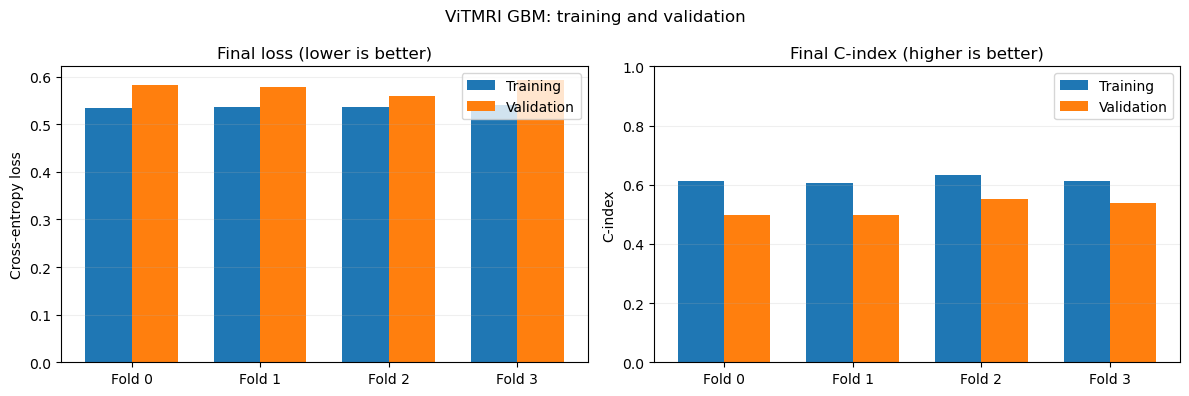

Mean training C-index: 0.615
Mean validation C-index: 0.521
Mean training loss: 0.537
Mean validation loss: 0.578


In [111]:
SUMMARY_PATH = ROOT / "result/ViT/gbm/summary.csv"
summary = pd.read_csv(SUMMARY_PATH)
print("Training/validation summary:", SUMMARY_PATH)
folds = summary[summary["fold"].astype(str) != "average"].copy()
folds["fold"] = folds["fold"].astype(int)
folds = folds.sort_values("fold")
display(folds[["fold", "train_loss", "final_val_loss", "train_cindex", "final_val_cindex"]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(len(folds))
for ax, train_col, val_col, title in [
    (axes[0], "train_loss", "final_val_loss", "Final loss (lower is better)"),
    (axes[1], "train_cindex", "final_val_cindex", "Final C-index (higher is better)"),
]:
    ax.bar(x - 0.18, folds[train_col], width=0.36, label="Training")
    ax.bar(x + 0.18, folds[val_col], width=0.36, label="Validation")
    ax.set_xticks(x, [f"Fold {fold}" for fold in folds["fold"]])
    ax.set_title(title)
    ax.legend()
    ax.grid(axis="y", alpha=0.2)
axes[0].set_ylabel("Cross-entropy loss")
axes[1].set_ylabel("C-index")
axes[1].set_ylim(0, 1)
fig.suptitle(f"ViTMRI {SUMMARY_PATH.parent.name.upper()}: training and validation")
fig.tight_layout()
save_plot(f"ViT_{SUMMARY_PATH.parent.name}_training_validation.png")
plt.show()

print(f"Mean training C-index: {folds['train_cindex'].mean():.3f}")
print(f"Mean validation C-index: {folds['final_val_cindex'].mean():.3f}")

print(f"Mean training loss: {folds['train_loss'].mean():.3f}")
print(f"Mean validation loss: {folds['final_val_loss'].mean():.3f}")



Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/ViT_gbm_epoch_curves.png


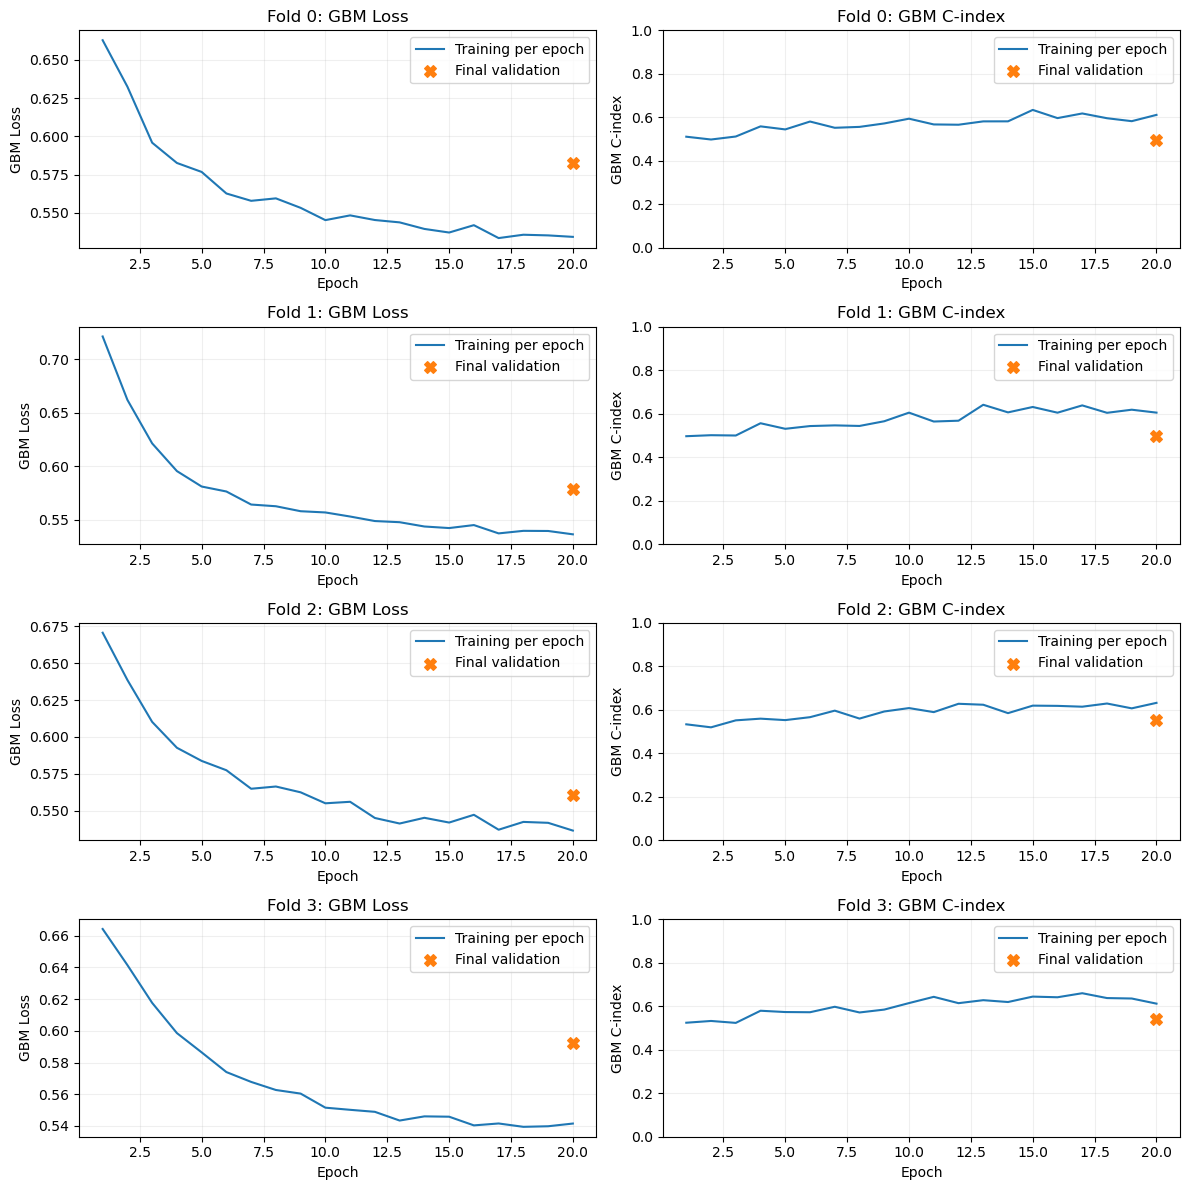

In [112]:
# Plot epoch training curves and the final validation point for each fold.
histories = {}
for _, row in folds.iterrows():
    fold = int(row["fold"])
    path = SUMMARY_PATH.parent / f"training_history_fold_{fold}.csv"
    if not path.exists():
        print(f"Fold {fold}: no saved GBM history at {path}. Rerun script/mri.sh to generate it.")
        continue
    history = pd.read_csv(path)
    if history.empty or not {"train_loss", "train_cindex"}.issubset(history.columns):
        print(f"Skipping fold {fold}: missing training metrics.")
        continue
    if not np.allclose(history.iloc[-1][["train_loss", "train_cindex"]].to_numpy(dtype=float),
                       [row["train_loss"], row["train_cindex"]], rtol=1e-4, atol=1e-6):
        print(f"Skipping fold {fold}: history does not match the MRI summary.")
        continue
    histories[fold] = history

if histories:
    fig, axes = plt.subplots(len(histories), 2, figsize=(12, 3 * len(histories)), squeeze=False)
    for index, (fold, history) in enumerate(histories.items()):
        row = folds.set_index("fold").loc[fold]
        epochs = np.arange(1, len(history) + 1)
        for ax, train_col, val_col, ylabel in [
            (axes[index, 0], "train_loss", "final_val_loss", "GBM Loss"),
            (axes[index, 1], "train_cindex", "final_val_cindex", "GBM C-index"),
        ]:
            ax.plot(epochs, history[train_col], label="Training per epoch")
            ax.scatter(epochs[-1], row[val_col], color="tab:orange", marker="X", s=70,
                       label="Final validation", zorder=3)
            ax.set(title=f"Fold {fold}: {ylabel}", xlabel="Epoch", ylabel=ylabel)
            ax.grid(alpha=0.2)
            ax.legend()
        axes[index, 1].set_ylim(0, 1)
    fig.tight_layout()
    save_plot(f"ViT_{SUMMARY_PATH.parent.name}_epoch_curves.png")
    plt.show()
else:
    print("No matching MRI epoch histories; use the final fold comparison above.")


## Preview the larger MRI validation split
The MRI script now uses **3 folds**, giving about 67% training and 33% validation per fold. This is a preview of the new split, not results from a retrained model. Existing prediction CSVs still describe their original training runs. All scans from a patient stay together.

Run this section independently to see counts and example slices. Set `FOLD` to 0, 1, or 2. Preview images are center slices, not tumor-selected slices.


MRI dataset: 83 patients, 408 images
Preview: fold 0 of 3
            Patients  Images
Training          55     220
Validation        28     112


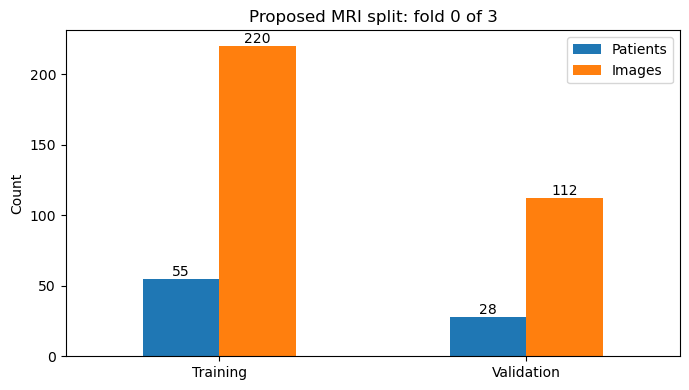

In [113]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
if not (root / "dataset").is_dir():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
from dataset.SurvivalMRIDataset import SurvivalMRIDataset

N_FOLDS = 3  # Match --n_folds in script/mri.sh.
FOLD = 0
if not 0 <= FOLD < N_FOLDS:
    raise ValueError("FOLD must be between 0 and N_FOLDS - 1.")
mri = SurvivalMRIDataset(
    label_file=root / "dataset_csv/metadata/clinical_gbm.csv",
    mri_file_name=root / "dataset_csv/mri_data/gbm_mri_metadata.csv",
    mri_dir="/media/licongcong/Data 1/TCGA-GBM/MRI-images",
    seed=42, label_col="CDE_survival_time", n_bins=4, n_classes=4,
    crop_size=(224, 224, 224),
)
validation_patients = mri.metadata.iloc[FOLD::N_FOLDS]["patient_id"]
is_validation = mri.metadata["patient_id"].isin(validation_patients)
preview_splits = {}
for name, patient_rows in [("Training", mri.metadata[~is_validation]),
                           ("Validation", mri.metadata[is_validation])]:
    preview_splits[name] = patient_rows.merge(mri.mri_data, on="patient_id", how="inner")
assert set(preview_splits["Training"].patient_id).isdisjoint(preview_splits["Validation"].patient_id)
counts = pd.DataFrame({
    name: {"Patients": frame.patient_id.nunique(), "Images": len(frame)}
    for name, frame in preview_splits.items()
}).T
print(f"Preview: fold {FOLD} of {N_FOLDS}")
print(counts.to_string())
export_dir = root / "result/comparisons/mri_visualization"
export_dir.mkdir(parents=True, exist_ok=True)
ax = counts.plot.bar(figsize=(7, 4), rot=0, color=["tab:blue", "tab:orange"])
for container in ax.containers:
    ax.bar_label(container)
ax.set(title=f"Proposed MRI split: fold {FOLD} of {N_FOLDS}", ylabel="Count")
plt.tight_layout()
plt.savefig(export_dir / f"gbm_{N_FOLDS}fold_{FOLD}_split_counts.png", dpi=300)
plt.show()


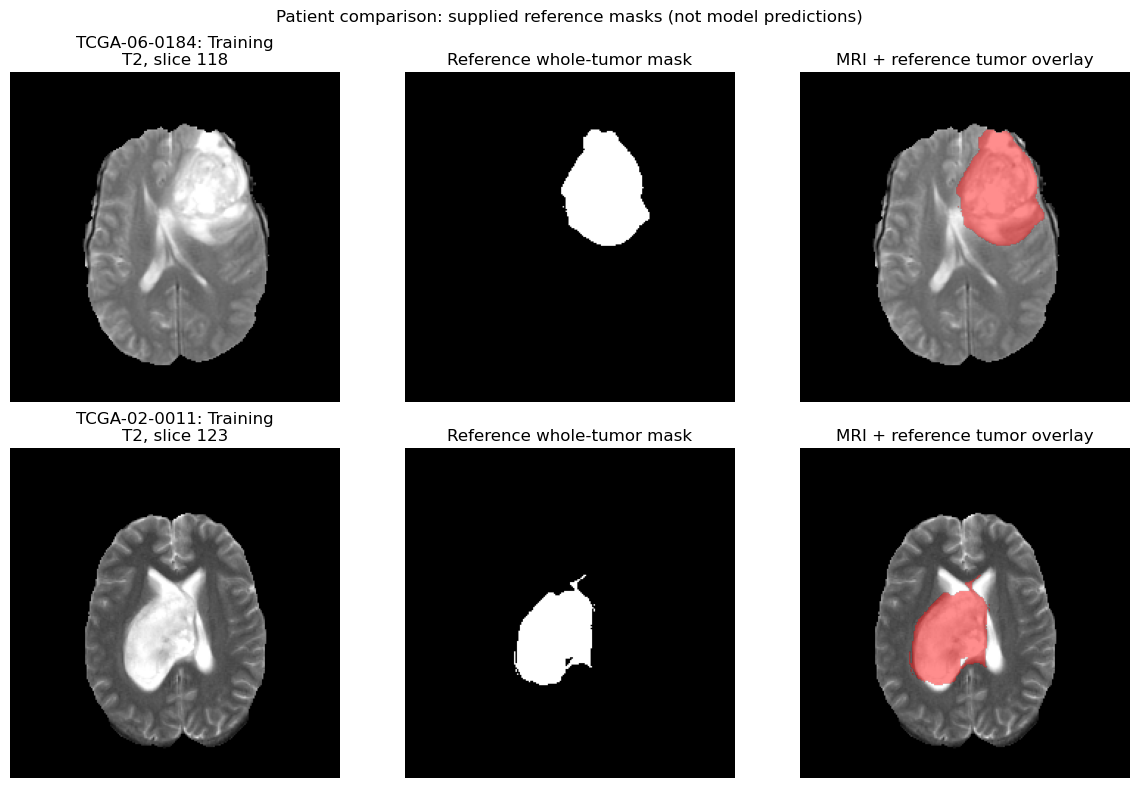

,Patient,Split,Survival time (clinical units),Censorship (1=censored),Reference mask
0,TCGA-06-0184,Training,40.933333,1.0,TCGA-06-0184_2003.07.13_GlistrBoost_ManuallyCo...
1,TCGA-02-0011,Training,21.000000,0.0,TCGA-02-0011_1998.02.01_GlistrBoost_ManuallyCo...


Saved: /home/licongcong/Desktop/learning/medical_image_classification/BrainCanerSurvival/result/comparisons/mri_visualization/gbm_fold_0_two_patient_reference_comparison.png
Reference masks prefer manually corrected GlistrBoost annotations; all positive labels are shown as whole tumor.


In [114]:
# Compare two patients with their supplied reference tumor masks.
import nibabel as nib
from nibabel.processing import resample_from_to
from matplotlib.colors import ListedColormap
from IPython.display import display

PATIENT_IDS = ["TCGA-06-0184", "TCGA-02-0011"]
SEQUENCE = "t2"
fig, axes = plt.subplots(len(PATIENT_IDS), 3, figsize=(12, 8))
clinical_rows = []
for row, patient_id in enumerate(PATIENT_IDS):
    matches = [(name, frame[frame["patient_id"] == patient_id])
               for name, frame in preview_splits.items() if (frame["patient_id"] == patient_id).any()]
    if not matches:
        raise ValueError(f"Patient is not in the eligible dataset: {patient_id}")
    split_name, patient_scans = matches[0]
    paths = [Path(path) for path in patient_scans["image_path"]]
    paths = sorted(path for path in paths if path.name.lower().endswith(f"_{SEQUENCE}.nii.gz"))
    if not paths:
        raise FileNotFoundError(f"No {SEQUENCE} scan for {patient_id}")
    image_path = paths[0]
    # Match the reference mask to exactly the same patient and scan date.
    prefix = image_path.name.split(f"_{SEQUENCE}.")[0]
    masks = [path for path in image_path.parent.glob(prefix + "_*.nii*")
             if any(marker in path.name.lower() for marker in ("glistrboost", "glisterboots"))]
    if not masks:
        raise FileNotFoundError(f"No reference tumor mask for {image_path.name}")
    mask_path = sorted(masks, key=lambda path: ("manuallycorrected" not in path.name.lower(), path.name))[0]
    image = nib.as_closest_canonical(nib.load(str(image_path)))
    mask = nib.as_closest_canonical(nib.load(str(mask_path)))
    if mask.shape != image.shape or not np.allclose(mask.affine, image.affine):
        mask = resample_from_to(mask, (image.shape, image.affine), order=0)
    tumor_mask = np.rint(mask.get_fdata()).astype(np.int16).transpose(2, 1, 0)
    if mri.crop_size is not None:
        tumor_mask = mri.crop_mri_volume(tumor_mask, mri.crop_size)
    volume = mri.load_mri_series(str(image_path))[0].numpy()
    # Use the same slice for the scan, reference mask, and overlay.
    tumor_counts = (tumor_mask > 0).sum(axis=(1, 2))
    index = int(tumor_counts.argmax()) if tumor_counts.any() else volume.shape[0] // 2
    image_slice, mask_slice = volume[index], tumor_mask[index]
    foreground = image_slice[image_slice != 0]
    limits = np.percentile(foreground, [1, 99]) if foreground.size else (0, 1)
    axes[row, 0].imshow(image_slice, cmap="gray", origin="lower", vmin=limits[0], vmax=limits[1])
    axes[row, 0].set_title(f"{patient_id}: {split_name}\n{SEQUENCE.upper()}, slice {index}")
    axes[row, 1].imshow(mask_slice > 0, cmap="gray", origin="lower", vmin=0, vmax=1)
    axes[row, 1].set_title("Reference whole-tumor mask")
    axes[row, 2].imshow(image_slice, cmap="gray", origin="lower", vmin=limits[0], vmax=limits[1])
    axes[row, 2].imshow(np.ma.masked_where(mask_slice == 0, mask_slice > 0),
                        cmap=ListedColormap(["red"]), alpha=0.45, origin="lower")
    axes[row, 2].set_title("MRI + reference tumor overlay")
    for ax in axes[row]:
        ax.axis("off")
    clinical = patient_scans.iloc[0]
    clinical_rows.append({"Patient": patient_id, "Split": split_name,
                          "Survival time (clinical units)": clinical[mri.label_col],
                          "Censorship (1=censored)": clinical["censorship"],
                          "Reference mask": mask_path.name})
fig.suptitle("Patient comparison: supplied reference masks (not model predictions)")
fig.tight_layout()
output_path = export_dir / f"gbm_fold_{FOLD}_two_patient_reference_comparison.png"
fig.savefig(output_path, dpi=300, bbox_inches="tight")
plt.show()
display(pd.DataFrame(clinical_rows))
print("Saved:", output_path)
print("Reference masks prefer manually corrected GlistrBoost annotations; all positive labels are shown as whole tumor.")
